In [24]:
import pandas as pd

df = pd.read_json("/content/iam_anomaly_2026.jsonl", lines=True)

In [25]:
print("Shape:", df.shape)

Shape: (10378, 21)


In [26]:
df.head()

,timestamp,trace_id,module,event_type,level,user_id,action_by,ref_id,ref,client_ip,...,http_method,uri,http_status,duration_ms,referer,message,payload,label,category,subcategory
0,2026-01-01 01:15:57.736000+00:00,tr_4ab036a024824d4b,sp,sp_saml_login,INFO,None,None,c8qcpme6er87210brp1g4qbf9e3wzhzw,https://equipment.example.com/shibboleth,192.168.200.224,...,GET,/secure/dashboard,302,9,NaN,SAML login request,"{'federation': 'kafe', 'entityid': 'https://id...",attack,protocol_abuse,novel_saml_assertion_replay
1,2026-01-01 01:15:58.892000+00:00,tr_4ab036a024824d4b,idp,idp_sso_request,INFO,None,None,c8qcpme6er87210brp1g4qbf9e3wzhzw,https://equipment.example.com/shibboleth,192.168.200.224,...,GET,/idp/profile/SAML2/Redirect/SSO,200,75,NaN,SAML SSO request received,{},attack,protocol_abuse,novel_saml_assertion_replay
2,2026-01-01 01:16:00+00:00,tr_4ab036a024824d4b,sp,sp_saml_login,INFO,None,None,c8qcpme6er87210brp1g4qbf9e3wzhzw,https://equipment.example.com/shibboleth,192.168.200.224,...,GET,/secure/dashboard,302,15,NaN,SAML login request: ref_id=c8qcpme6er87210brp1...,"{'federation': 'kafe', 'entityid': 'https://id...",attack,protocol_abuse,novel_saml_assertion_replay
3,2026-01-01 01:16:06.615000+00:00,tr_4ab036a024824d4b,sp,sp_login_by_idp,INFO,e7vxe6wcf60aacgjhumon0clh0nhv8ml,None,c8qcpme6er87210brp1g4qbf9e3wzhzw,https://equipment.example.com/shibboleth,192.168.200.224,...,POST,/Shibboleth.sso/SAML2/POST,302,54,NaN,SAML SP ACS: Processing login_by_idp: ref_id=c...,"{'ref_id': 'c8qcpme6er87210brp1g4qbf9e3wzhzw',...",attack,protocol_abuse,novel_saml_assertion_replay
4,2026-01-01 01:16:07.625000+00:00,tr_4ab036a024824d4b,auth,auth_access_log_failed,LOG,e7vxe6wcf60aacgjhumon0clh0nhv8ml,None,c8qcpme6er87210brp1g4qbf9e3wzhzw,https://equipment.example.com/shibboleth,192.168.200.224,...,POST,/modules/core/auth/api/login,401,50,NaN,Access log: login failed,{'action': 'failed'},attack,protocol_abuse,novel_saml_assertion_replay


In [27]:
print(df.isnull().sum())

timestamp          0
trace_id           0
module             0
event_type         0
level              0
user_id         5967
action_by      10274
ref_id           626
ref              917
client_ip          0
user_agent      1064
http_method        0
uri                0
http_status        0
duration_ms        0
referer        10378
message            0
payload            0
label              0
category           0
subcategory     4644
dtype: int64


In [28]:
print("Duplicate rows:", df.astype(str).duplicated().sum())
#astype(str) is added as dataset is in json form

Duplicate rows: 0


In [29]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10378 entries, 0 to 10377
Data columns (total 21 columns):
 #   Column       Non-Null Count  Dtype              
---  ------       --------------  -----              
 0   timestamp    10378 non-null  datetime64[ns, UTC]
 1   trace_id     10378 non-null  object             
 2   module       10378 non-null  object             
 3   event_type   10378 non-null  object             
 4   level        10378 non-null  object             
 5   user_id      4411 non-null   object             
 6   action_by    104 non-null    object             
 7   ref_id       9752 non-null   object             
 8   ref          9461 non-null   object             
 9   client_ip    10378 non-null  object             
 10  user_agent   9314 non-null   object             
 11  http_method  10378 non-null  object             
 12  uri          10378 non-null  object             
 13  http_status  10378 non-null  int64              
 14  duration_ms  10378 non

In [30]:
df['event_type'].value_counts().head(15)
#event_type describes what action or activity occurred in the authentication system.

,count
event_type,
rp_oidc_login,1440
op_authorize_request,1259
auth_access_log_failed,1106
auth_access_log_success,1046
auth_login_attempt,800
auth_login_success,635
op_token_request,545
sp_saml_login,532
idp_sso_request,469


In [31]:
df['category'].value_counts()

,count
category,
login,3175
protocol_abuse,2366
logout,967
account_abuse,689
login_error,599
credential,498
access_anomaly,336
behavioral_attack,318
session,268


In [32]:
failed_df = df[df['event_type'].isin([
    'auth_access_log_failed',
    'auth_login_failed_rejected'
])].copy()

print("Failed login records:", len(failed_df))

Failed login records: 1265


In [33]:
failed_df = failed_df.set_index('timestamp')

login_counts = failed_df.resample('5min').size()

print(login_counts.head())

timestamp
2026-01-01 01:15:00+00:00    7
2026-01-01 01:20:00+00:00    0
2026-01-01 01:25:00+00:00    0
2026-01-01 01:30:00+00:00    0
2026-01-01 01:35:00+00:00    0
Freq: 5min, dtype: int64


In [34]:
import matplotlib.pyplot as plt

print("Matplotlib imported successfully")
print(type(login_counts))
print(login_counts.shape)

Matplotlib imported successfully
<class 'pandas.core.series.Series'>
(2183,)


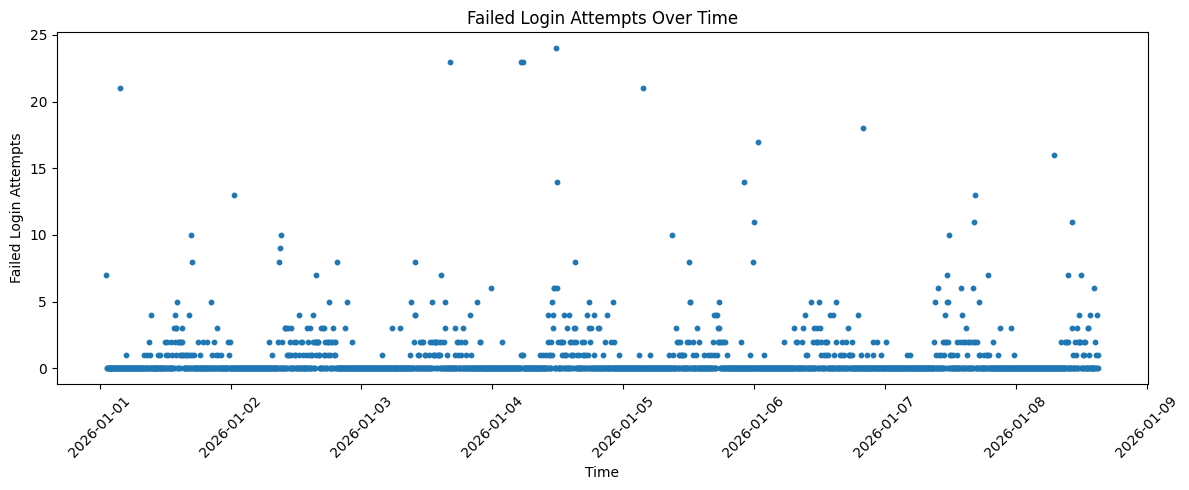

In [35]:
plt.figure(figsize=(12, 5))

plt.scatter(login_counts.index, login_counts.values, s=10)

plt.xlabel("Time")
plt.ylabel("Failed Login Attempts")
plt.title("Failed Login Attempts Over Time")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [36]:
print(login_counts.sort_values(ascending=False).head(10))
#10 failded login datapoints

timestamp
2026-01-04 11:45:00+00:00    24
2026-01-04 05:35:00+00:00    23
2026-01-03 16:20:00+00:00    23
2026-01-04 05:15:00+00:00    23
2026-01-01 03:40:00+00:00    21
2026-01-05 03:40:00+00:00    21
2026-01-06 20:05:00+00:00    18
2026-01-06 00:40:00+00:00    17
2026-01-08 07:05:00+00:00    16
2026-01-05 22:15:00+00:00    14
dtype: int64


In [37]:
model_df = login_counts.to_frame(name='failed_login_count')

print(model_df.head())
#This gives us one column containing failed login counts for every 5-minute interval.

                           failed_login_count
timestamp                                    
2026-01-01 01:15:00+00:00                   7
2026-01-01 01:20:00+00:00                   0
2026-01-01 01:25:00+00:00                   0
2026-01-01 01:30:00+00:00                   0
2026-01-01 01:35:00+00:00                   0


In [38]:
model_df['hour'] = model_df.index.hour
model_df['day'] = model_df.index.dayofweek
print(model_df.head())
#we are extracting hours and data count from timestamp

                           failed_login_count  hour  day
timestamp                                               
2026-01-01 01:15:00+00:00                   7     1    3
2026-01-01 01:20:00+00:00                   0     1    3
2026-01-01 01:25:00+00:00                   0     1    3
2026-01-01 01:30:00+00:00                   0     1    3
2026-01-01 01:35:00+00:00                   0     1    3


In [39]:
model_df['previous_login_count'] = model_df['failed_login_count'].shift(1)

print(model_df.head())
#getting login failded  for 5 min interval
#shift(1) is for 1 line shift at starting

                           failed_login_count  hour  day  previous_login_count
timestamp                                                                     
2026-01-01 01:15:00+00:00                   7     1    3                   NaN
2026-01-01 01:20:00+00:00                   0     1    3                   7.0
2026-01-01 01:25:00+00:00                   0     1    3                   0.0
2026-01-01 01:30:00+00:00                   0     1    3                   0.0
2026-01-01 01:35:00+00:00                   0     1    3                   0.0


In [40]:
model_df['rolling_avg'] = (
    model_df['failed_login_count'].shift(1).rolling(window=3).mean()
)

print(model_df.head(10))

                           failed_login_count  hour  day  \
timestamp                                                  
2026-01-01 01:15:00+00:00                   7     1    3   
2026-01-01 01:20:00+00:00                   0     1    3   
2026-01-01 01:25:00+00:00                   0     1    3   
2026-01-01 01:30:00+00:00                   0     1    3   
2026-01-01 01:35:00+00:00                   0     1    3   
2026-01-01 01:40:00+00:00                   0     1    3   
2026-01-01 01:45:00+00:00                   0     1    3   
2026-01-01 01:50:00+00:00                   0     1    3   
2026-01-01 01:55:00+00:00                   0     1    3   
2026-01-01 02:00:00+00:00                   0     2    3   

                           previous_login_count  rolling_avg  
timestamp                                                     
2026-01-01 01:15:00+00:00                   NaN          NaN  
2026-01-01 01:20:00+00:00                   7.0          NaN  
2026-01-01 01:25:00+00:00  

In [41]:
model_df = model_df.dropna()

print(model_df.isnull().sum())
print("Final dataset shape:", model_df.shape)

failed_login_count      0
hour                    0
day                     0
previous_login_count    0
rolling_avg             0
dtype: int64
Final dataset shape: (2180, 5)


In [42]:
split_index = int(len(model_df) * 0.8)

train = model_df.iloc[:split_index]
test = model_df.iloc[split_index:]

print("Training records:", len(train))
print("Testing records:", len(test))

Training records: 1744
Testing records: 436


In [43]:
features = ['hour', 'day', 'previous_login_count', 'rolling_avg']

X_train = train[features]
y_train = train['failed_login_count']

X_test = test[features]
y_test = test['failed_login_count']

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: (1744, 4)
y_train: (1744,)
X_test: (436, 4)
y_test: (436,)


In [44]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_train, y_train)

print("Model training completed successfully!")

Model training completed successfully!


In [45]:
y_pred = model.predict(X_test)

print("Actual values:", y_test.values[:10])
print("Predicted values:", y_pred[:10])

Actual values: [0 0 0 0 0 0 0 0 0 0]
Predicted values: [0.29594406 0.29594406 0.31190766 0.31190766 0.31190766 0.31190766
 0.31190766 0.31190766 0.31190766 0.31190766]


In [46]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print("MAE:", mae)
print("RMSE:", rmse)

MAE: 0.8697945860532746
RMSE: 1.7066217751918444


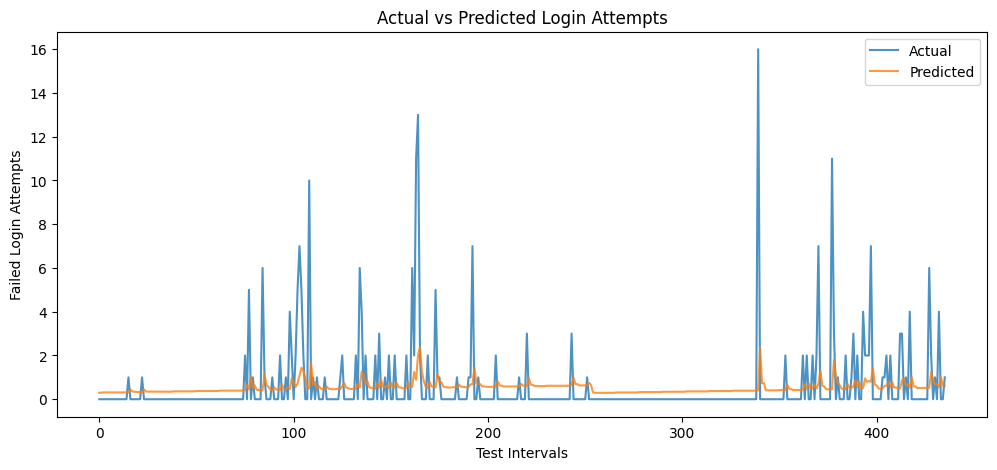

In [47]:
plt.figure(figsize=(12, 5))

plt.plot(y_test.values, label='Actual', alpha=0.8)
plt.plot(y_pred, label='Predicted', alpha=0.8)

plt.xlabel("Test Intervals")
plt.ylabel("Failed Login Attempts")
plt.title("Actual vs Predicted Login Attempts")
plt.legend()
plt.show()

In [48]:
results = test.copy()

results['predicted'] = y_pred
results['residual'] = results['failed_login_count'] - results['predicted']

print(results.head())

                           failed_login_count  hour  day  \
timestamp                                                  
2026-01-07 02:50:00+00:00                   0     2    2   
2026-01-07 02:55:00+00:00                   0     2    2   
2026-01-07 03:00:00+00:00                   0     3    2   
2026-01-07 03:05:00+00:00                   0     3    2   
2026-01-07 03:10:00+00:00                   0     3    2   

                           previous_login_count  rolling_avg  predicted  \
timestamp                                                                 
2026-01-07 02:50:00+00:00                   0.0          0.0   0.295944   
2026-01-07 02:55:00+00:00                   0.0          0.0   0.295944   
2026-01-07 03:00:00+00:00                   0.0          0.0   0.311908   
2026-01-07 03:05:00+00:00                   0.0          0.0   0.311908   
2026-01-07 03:10:00+00:00                   0.0          0.0   0.311908   

                           residual  
timestamp      